<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp13_Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 13: Car Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement the Car Price Prediction Model using Python.

## Background
Predicting a used-car **selling price** is a *regression* problem. Typical drivers are the car's **age**, **kilometres driven**, **showroom (present) price**, fuel type, transmission, seller type and number of previous owners. Prices are right-skewed and depreciate multiplicatively, so we model `log(price)` and convert predictions back. Models are compared with **MAE, RMSE and R-squared**.


## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We generate a dataset of **1,500 used cars** modelled on the popular *CarDekho* data (prices in lakh INR). Selling price follows realistic depreciation: it falls with age and mileage, is higher for diesel and automatic cars, and lower for individual sellers and multiple owners. Saved as `car_data.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 1500
CURRENT_YEAR = 2024        # reference year used to compute car age

year = rng.randint(2005, 2024, n)
age = CURRENT_YEAR - year
present_price = np.clip(rng.lognormal(1.9, 0.75, n), 1.5, 60).round(2)           # showroom price, lakhs
fuel = rng.choice(["Petrol", "Diesel", "CNG"], n, p=[0.60, 0.35, 0.05])
seller = rng.choice(["Dealer", "Individual"], n, p=[0.40, 0.60])
trans = rng.choice(["Manual", "Automatic"], n, p=[0.85, 0.15])
owner = rng.choice([0, 1, 3], n, p=[0.85, 0.13, 0.02])
kms = np.clip(rng.normal(age * 9000 + 5000, 8000 + age * 1500), 500, 300000).round(-2)

selling = (present_price * np.exp(-0.11 * age)
           * (1 + 0.18 * (fuel == "Diesel") + 0.25 * (trans == "Automatic") - 0.10 * (fuel == "CNG"))
           * np.where(seller == "Individual", 0.93, 1.0)
           * np.select([owner == 1, owner == 3], [0.93, 0.75], 1.0)
           * np.exp(-kms / 1e6)
           * rng.lognormal(0, 0.10, n))
selling = np.clip(selling, 0.1, None).round(2)

pd.DataFrame({"Year": year, "Selling_Price": selling, "Present_Price": present_price, "Kms_Driven": kms,
              "Fuel_Type": fuel, "Seller_Type": seller, "Transmission": trans, "Owner": owner}).to_csv("car_data.csv", index=False)
print("Saved car_data.csv")

Saved car_data.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("car_data.csv")
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2011,3.15,13.32,156500.0,Petrol,Dealer,Manual,0
1,2019,5.61,10.12,76400.0,Diesel,Dealer,Manual,0
2,2015,3.31,7.22,75000.0,Petrol,Individual,Automatic,0
3,2012,1.45,5.44,63300.0,Petrol,Individual,Manual,0
4,2011,1.51,7.83,143200.0,Petrol,Individual,Manual,0


## Step 3: Data Preprocessing
1. Feature engineering (in a reusable `add_features` function): `Car_Age = 2024 - Year` and `Log_Present_Price = log(Present_Price)` - depreciation is multiplicative, so on a log scale price depends *linearly* on log showroom price.  2. Separate numeric / categorical columns.  3. Train/test split.  4. One-hot encode categoricals and scale numerics in a `ColumnTransformer`.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
def add_features(d):
    d = d.copy()
    if "Year" in d.columns:
        d["Car_Age"] = 2024 - d["Year"]
    d["Log_Present_Price"] = np.log(d["Present_Price"])
    return d

df = add_features(df).drop(columns="Year")

target = "Selling_Price"
num_cols = ["Log_Present_Price", "Kms_Driven", "Car_Age", "Owner"]
cat_cols = ["Fuel_Type", "Seller_Type", "Transmission"]
X, y = df[num_cols + cat_cols], df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([("num", StandardScaler(), num_cols),
                                  ("cat", OneHotEncoder(drop="first"), cat_cols)])
print("Train:", X_train.shape, "Test:", X_test.shape)

Missing values: 0 | Duplicates: 0
Train: (1200, 7) Test: (300, 7)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print(df.describe().T.round(2))

                    count      mean       std     min       25%       50%  \
Selling_Price      1500.0      3.53      4.39    0.15      1.05      2.08   
Present_Price      1500.0      9.29      8.16    1.50      4.08      7.01   
Kms_Driven         1500.0  96120.20  56194.07  500.00  48675.00  90600.00   
Owner              1500.0      0.19      0.55    0.00      0.00      0.00   
Car_Age            1500.0     10.17      5.59    1.00      5.00     10.00   
Log_Present_Price  1500.0      1.94      0.76    0.41      1.41      1.95   

                         75%        max  
Selling_Price           4.30      62.28  
Present_Price          11.66      60.00  
Kms_Driven         138650.00  274600.00  
Owner                   0.00       3.00  
Car_Age                15.00      19.00  
Log_Present_Price       2.46       4.09  


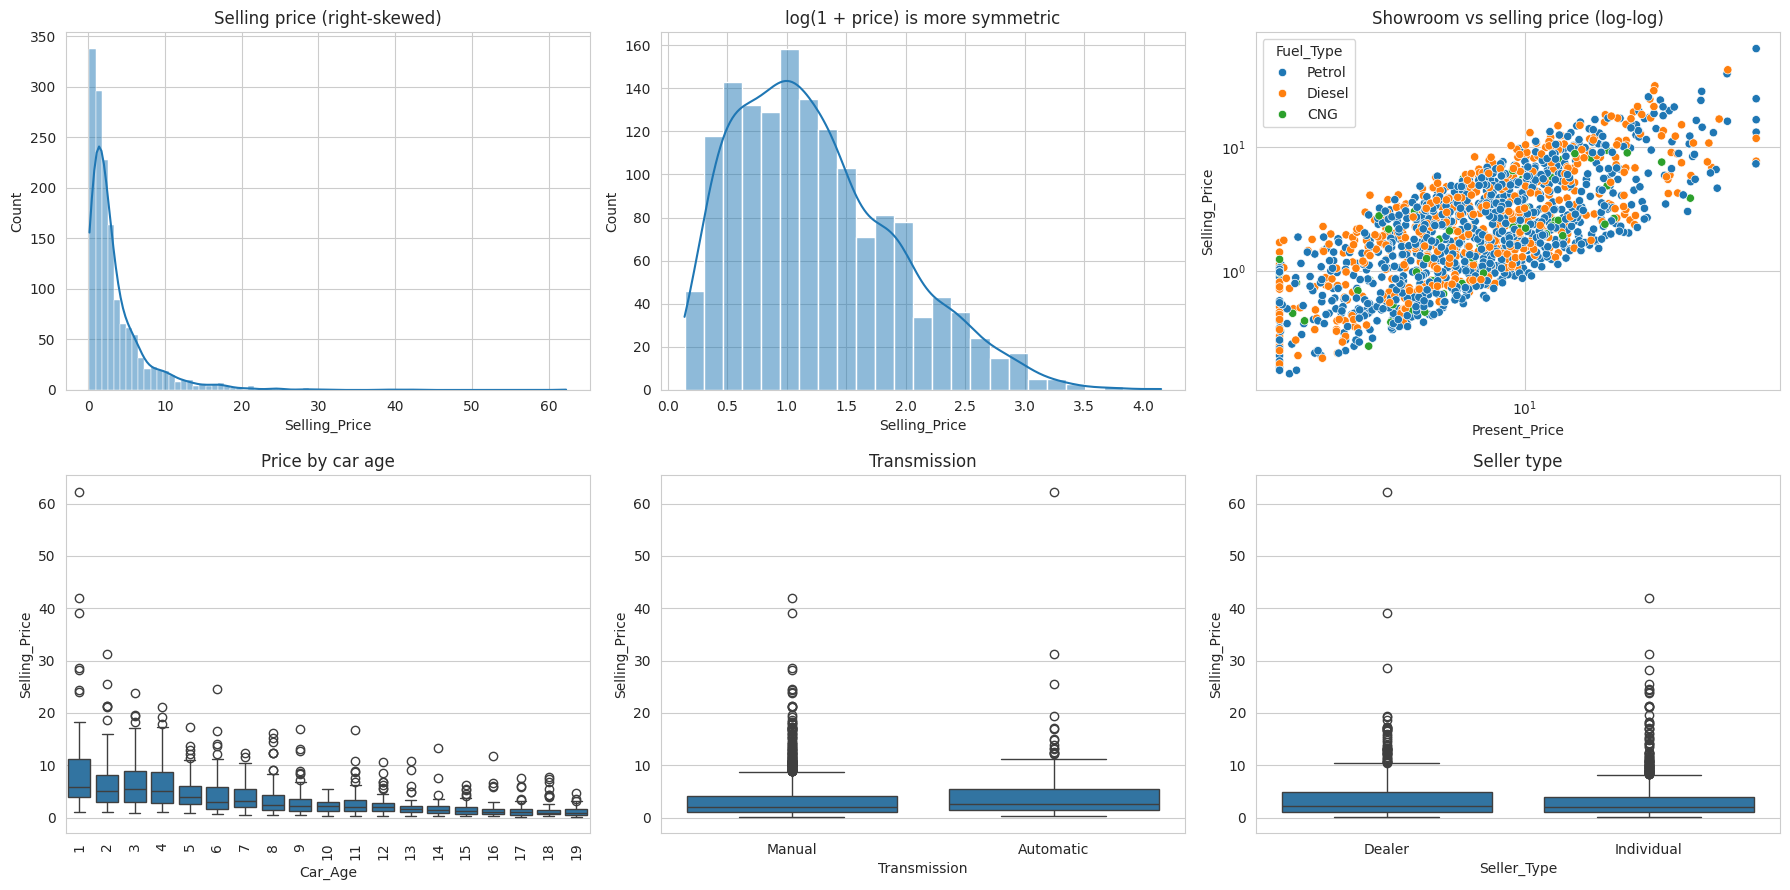

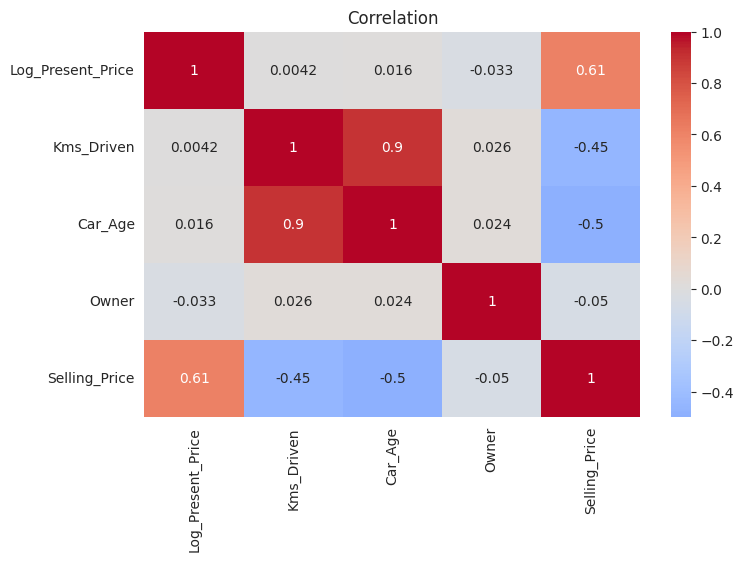

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(df[target], kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Selling price (right-skewed)")
sns.histplot(np.log1p(df[target]), kde=True, ax=axes[0, 1]); axes[0, 1].set_title("log(1 + price) is more symmetric")
sns.scatterplot(data=df, x="Present_Price", y=target, hue="Fuel_Type", ax=axes[0, 2])
axes[0, 2].set_xscale("log"); axes[0, 2].set_yscale("log"); axes[0, 2].set_title("Showroom vs selling price (log-log)")
sns.boxplot(data=df, x="Car_Age", y=target, ax=axes[1, 0]); axes[1, 0].set_title("Price by car age"); axes[1, 0].tick_params(axis="x", rotation=90)
sns.boxplot(data=df, x="Transmission", y=target, ax=axes[1, 1]); axes[1, 1].set_title("Transmission")
sns.boxplot(data=df, x="Seller_Type", y=target, ax=axes[1, 2]); axes[1, 2].set_title("Seller type")
plt.tight_layout(); plt.show()

sns.heatmap(df[num_cols + [target]].corr(), annot=True, cmap="coolwarm", center=0); plt.title("Correlation"); plt.show()

## Step 5: Model Training
We compare four regressors. Each is wrapped in a pipeline and in a `TransformedTargetRegressor`, which trains on `log(1 + price)` and automatically converts predictions back to lakhs.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def make(regressor, log=True):
    pipe = Pipeline([("prep", preprocessor), ("model", regressor)])
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

models = {
    "Linear Regression": make(LinearRegression()),
    "Ridge Regression": make(Ridge(alpha=1.0)),
    "Random Forest": make(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    "Gradient Boosting": make(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)),
}
for name, m in models.items():
    m.fit(X_train, y_train)
print("All models trained.")

# Why the log transform helps: plain linear regression on the raw price
raw_linear = make(LinearRegression(), log=False).fit(X_train, y_train)
print("Linear Regression R2 on raw price :", round(raw_linear.score(X_test, y_test), 4))
print("Linear Regression R2 on log price :", round(models["Linear Regression"].score(X_test, y_test), 4))

All models trained.
Linear Regression R2 on raw price : 0.6731
Linear Regression R2 on log price : 0.8834


## Step 6: Model Evaluation
Compare the models on the test set (in lakhs), with 5-fold CV R-squared as a robustness check, then inspect the best model's predictions, residuals and feature importance.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p), "CV R2 (5-fold)": cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()})
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("R2", ascending=False)
print(results)
best_name = results.index[0]
best = models[best_name]
print("\nBest model:", best_name)

                     MAE   RMSE     R2  CV R2 (5-fold)
Model                                                 
Gradient Boosting  0.359  0.650  0.979           0.959
Random Forest      0.491  1.026  0.947           0.921
Ridge Regression   0.627  1.520  0.883           0.876
Linear Regression  0.626  1.516  0.883           0.877

Best model: Gradient Boosting


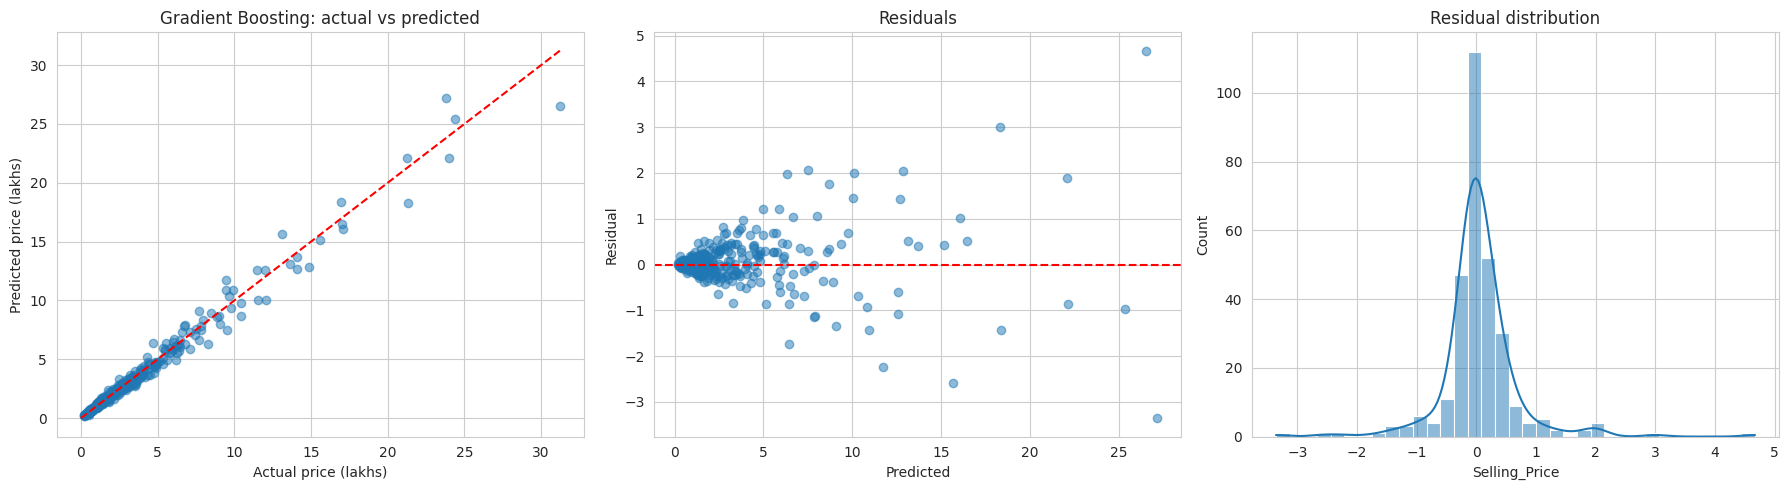

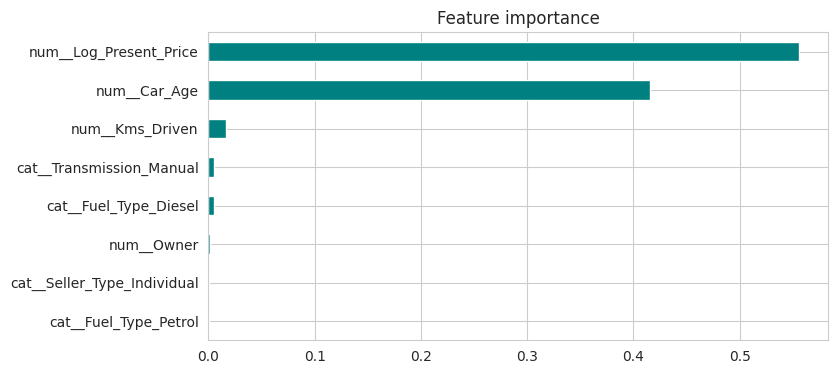

In [9]:
pred = best.predict(X_test)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, pred, alpha=.5); lim = [0, max(y_test.max(), pred.max())]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Actual price (lakhs)"); axes[0].set_ylabel("Predicted price (lakhs)"); axes[0].set_title(f"{best_name}: actual vs predicted")
res = y_test - pred
axes[1].scatter(pred, res, alpha=.5); axes[1].axhline(0, color="r", linestyle="--"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
sns.histplot(res, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

inner = best.regressor_.named_steps["model"]
if hasattr(inner, "feature_importances_"):
    names = best.regressor_.named_steps["prep"].get_feature_names_out()
    pd.Series(inner.feature_importances_, index=names).sort_values().plot(kind="barh", color="teal", figsize=(8, 4))
    plt.title("Feature importance"); plt.show()

## Step 7: Prediction on New Data
Predict the resale value of new cars and save the trained model for later use.

In [10]:
import joblib

new_cars = pd.DataFrame([
    {"Present_Price": 9.5,  "Kms_Driven": 35000, "Car_Age": 4,  "Owner": 0, "Fuel_Type": "Petrol", "Seller_Type": "Dealer",     "Transmission": "Manual"},
    {"Present_Price": 18.0, "Kms_Driven": 90000, "Car_Age": 8,  "Owner": 1, "Fuel_Type": "Diesel", "Seller_Type": "Individual", "Transmission": "Automatic"},
])
features_new = add_features(new_cars)[num_cols + cat_cols]        # same feature engineering as training
new_cars["Predicted_Selling_Price_Lakhs"] = best.predict(features_new).round(2)
print(new_cars)

joblib.dump(best, "car_price_model.joblib")
print("\nModel saved to car_price_model.joblib (reload with joblib.load).")

   Present_Price  Kms_Driven  Car_Age  Owner Fuel_Type Seller_Type  \
0            9.5       35000        4      0    Petrol      Dealer   
1           18.0       90000        8      1    Diesel  Individual   

  Transmission  Predicted_Selling_Price_Lakhs  
0       Manual                           6.21  
1    Automatic                           8.71  

Model saved to car_price_model.joblib (reload with joblib.load).


## Conclusion
Gradient Boosting was best (test R-squared about 0.98, CV about 0.96), Random Forest next (about 0.95), and the linear models reached about 0.88. Modelling log(price) with a log showroom-price feature lifted plain linear regression from about 0.67 to about 0.88 because depreciation is multiplicative; trees still win since they capture interactions (e.g. diesel x age, mileage effects). Showroom price and car age dominate the importance ranking. For real deployment, retrain on real marketplace data and monitor drift as prices change.